## Olist Customer Analytics | Python Analysis

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Customer Retention Analysis 

In [24]:
#load the cohort retentiom dataset
df = pd.read_csv('../data/cohort_retention.csv')

In [25]:
df.head()

,cohort_month,cohort_size,month_0,month_1,month_2,month_3
0,2017-01-01,717,100.0,0.28,0.28,0.14
1,2017-02-01,1628,100.0,0.18,0.31,0.12
2,2017-03-01,2503,100.0,0.44,0.36,0.40
3,2017-04-01,2256,100.0,0.62,0.22,0.18
4,2017-05-01,3451,100.0,0.46,0.46,0.29


In [26]:
# converting the 'cohort_month' column to datetime format
df['cohort_month'] = pd.to_datetime(df['cohort_month'])

# creating a readable month label
df['cohort_label'] = df['cohort_month'].dt.strftime("%b %Y")

# selecting the retention columns
retention_matrix = df.set_index("cohort_label")[
    ["month_0", "month_1", "month_2", "month_3"]
]

retention_matrix.head()

,month_0,month_1,month_2,month_3
cohort_label,,,,
Jan 2017,100.0,0.28,0.28,0.14
Feb 2017,100.0,0.18,0.31,0.12
Mar 2017,100.0,0.44,0.36,0.40
Apr 2017,100.0,0.62,0.22,0.18
May 2017,100.0,0.46,0.46,0.29


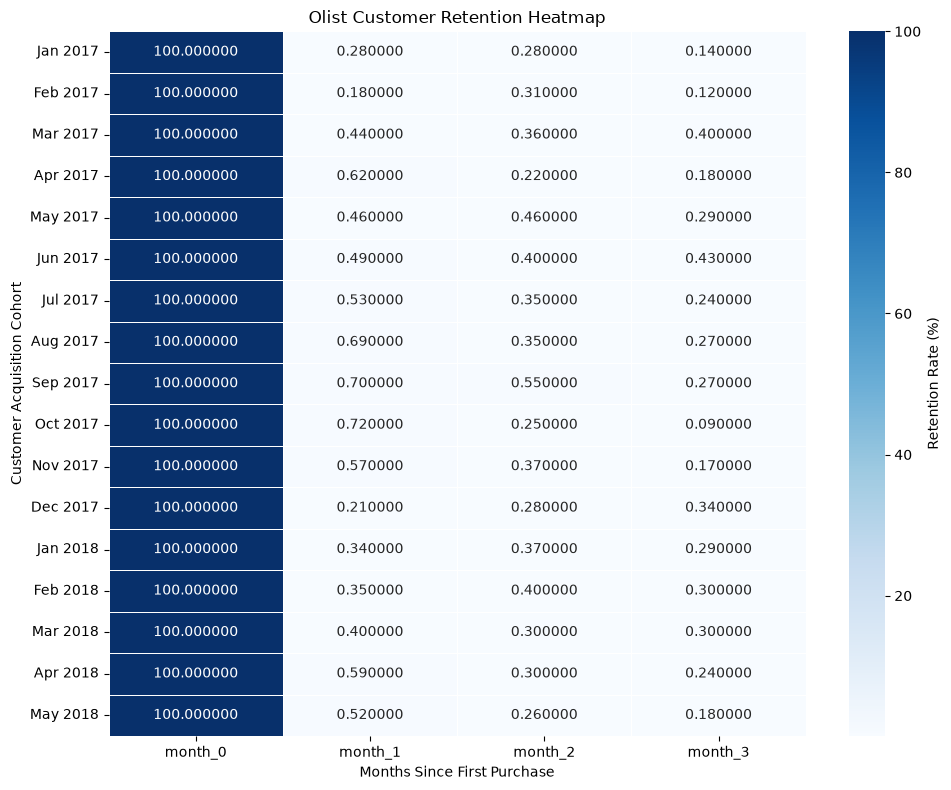

In [27]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    retention_matrix,
    annot=True,
    fmt="2f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Retention Rate (%)"}
)

plt.title("Olist Customer Retention Heatmap")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Acquisition Cohort")

plt.tight_layout()
plt.show()

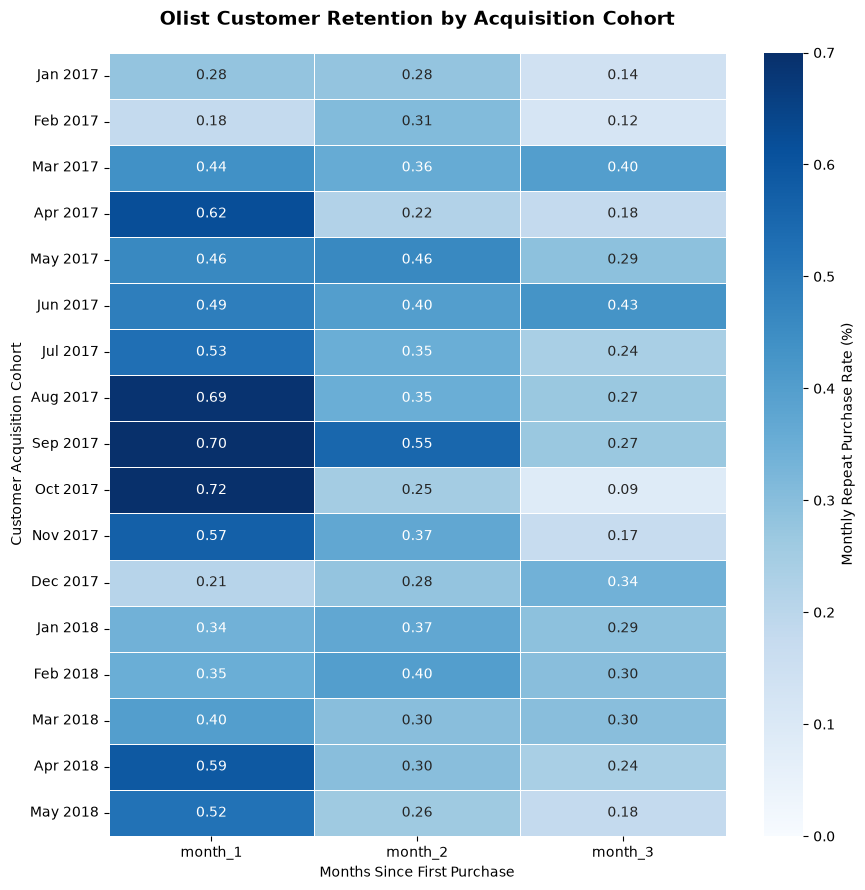

In [28]:
# Select only months 1 to 3
retention_heatmap = retention_matrix[
    ["month_1", "month_2", "month_3"]
].copy()

# Focus on cohorts from January 2017 onward
retention_heatmap = retention_heatmap.loc["Jan 2017":]

# Create the improved heatmap
plt.figure(figsize=(9, 9))

sns.heatmap(
    retention_heatmap,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5,
    vmin=0,
    vmax=0.7,
    cbar_kws={"label": "Monthly Repeat Purchase Rate (%)"}
)

plt.title(
    "Olist Customer Retention by Acquisition Cohort",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Acquisition Cohort")

plt.tight_layout()

# Save the visualization to project folder
plt.savefig(
    "../visuals/olist_cohort_retention_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### RFM Customer Segmentation Analysis

In [29]:
#load RFM customrt segmentation results
rfm_df = pd.read_csv("../data/rfm_segments.csv")

In [30]:
rfm_df.head()

,customer_segment,number_of_customers,total_revenue,average_customer_spend,percentage_of_customers,percentage_of_revenue
0,Other Customers,63127,4976237.08,78.83,67.62,37.64
1,High-Value Inactive,14537,4050384.50,278.63,15.57,30.63
2,Recent High-Value First-Time,14492,3869470.57,267.01,15.52,29.27
3,Recent Repeat,1202,325405.96,270.72,1.29,2.46


In [31]:
rfm_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_segment         4 non-null      str    
 1   number_of_customers      4 non-null      int64  
 2   total_revenue            4 non-null      float64
 3   average_customer_spend   4 non-null      float64
 4   percentage_of_customers  4 non-null      float64
 5   percentage_of_revenue    4 non-null      float64
dtypes: float64(4), int64(1), str(1)
memory usage: 324.0 bytes


<Figure size 1200x600 with 0 Axes>

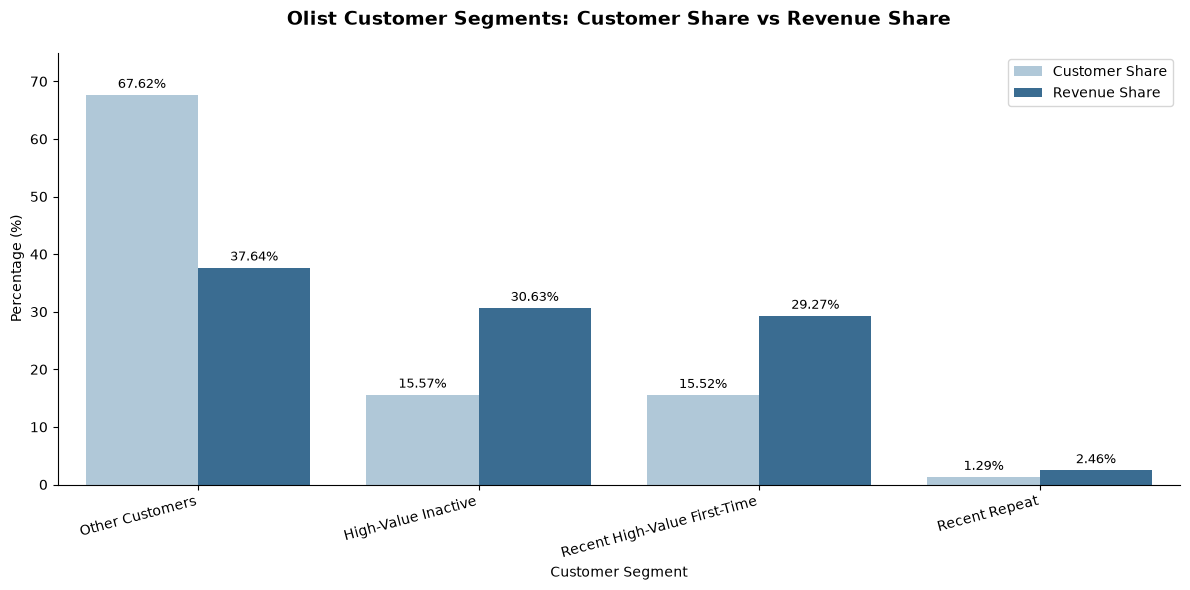

In [32]:
#visualize the distribution of RFM segments
plt.figure(figsize=(12, 6))

# Prepare data for visualization
rfm_plot = rfm_df.melt(
    id_vars="customer_segment",
    value_vars=[
        "percentage_of_customers",
        "percentage_of_revenue"
    ],
    var_name="metric",
    value_name="percentage"
)

# Rename the metrics for the legend
rfm_plot["metric"] = rfm_plot["metric"].replace({
    "percentage_of_customers": "Customer Share",
    "percentage_of_revenue": "Revenue Share"
})

# Create the chart
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=rfm_plot,
    x="customer_segment",
    y="percentage",
    hue="metric",
    hue_order=["Customer Share", "Revenue Share"],
    palette=["#A9C9DF", "#2C6E9F"]
)

# Add percentage labels above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3,
        fontsize=9
    )

# Format the chart
plt.title(
    "Olist Customer Segments: Customer Share vs Revenue Share",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.xlabel("Customer Segment")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, 75)
plt.legend(title="")

# Remove unnecessary borders
sns.despine()

plt.tight_layout()

# Save the final visualization
plt.savefig(
    "../visuals/olist_rfm_segment_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
